In [1]:
# conda env 'at3d_pure'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import netCDF4 as nc
from collections import OrderedDict
from util import load_sensor_dict
from util import save_sensor_dict

In [2]:
## INPUT
obs_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/AT3D_OBS_CAMP2Ex_RF17_default_1400.nc'
rte_grid_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/RTG_1400.nc'
background_scatterers_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/MIXTURE_default_0p250.nc'
# cloud_volume_mask_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_all_cloud_1400.nc'
config_file_name = '/data/keeling/a/johntl3/b/LundstromPub2025/NK1990_1D_Retrieval/misr_1D_config.json'
# config_file_name = '/data/keeling/a/johntl3/b/LundstromPub2025/configs/misr_config.json'
surface_wind_speed = 0.67 # m/s
# Reff(z) = a*z + b
a = 4.292 # um / km
b = 2.623 # um

# Mie table directory
mie_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/mie_tables/'

## OUTPUT
out_file = './LUT_1DRT.nc'
sd_out = './OBS_1DRT.nc'


In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
obs = load_sensor_dict(obs_file)

In [4]:
forward_sensors = at3d.containers.SensorsDict()
sensor = at3d.sensor.orthographic_projection(
    wavelength=0.67,
    bounding_box=rte_grid,
    x_resolution=0.275,
    y_resolution=0.275,
    azimuth=0,
    zenith=0,
    altitude='TOA',
    stokes='I',
    sub_pixel_ray_args={'method': None}
)
sensor = sensor.assign_attrs(mu0=obs['MISR']['sensor_list'][4].mu0)
sensor = sensor.assign_attrs(SAA=obs['MISR']['sensor_list'][4].SAA)
forward_sensors.add_sensor('MISR', sensor)

In [5]:
wavelength = 0.67

# Surface wind speed comes from ERA5 reanalysis - 
# see ./ancillary/CAMP2Ex_RF17_ERA5_Surface.ipynb
surfaces = OrderedDict()
m_water = 1.33197 - 1j*2.41e-8
surfaces[wavelength] = at3d.surface.wave_fresnel(np.real(m_water), np.imag(m_water), surface_wind_speed)

numerical_parameters = OrderedDict()
numerical_parameters[wavelength] = at3d.configuration.get_config(config_file_name)

sources = OrderedDict()
sources[wavelength] = at3d.source.solar(
    wavelength,
    -1*obs['MISR']['sensor_list'][0].mu0,
    obs['MISR']['sensor_list'][0].SAA,
    solarflux=1.0,
    skyrad=0.0
)

background_optical_scatterers = OrderedDict()
merged_properties = xr.load_dataset(background_scatterers_file)
background_optical_scatterers[wavelength] = {}
background_optical_scatterers[wavelength]['background'] = merged_properties

mie_mono_table = at3d.mie.get_mono_table(
    'Water',
    (wavelength, wavelength),
    max_integration_radius=65.0,
    minimum_effective_radius=5.5,
    relative_dir=mie_dir,
    verbose=False
)
mie_mono_tables = OrderedDict()
mie_mono_tables[wavelength] = mie_mono_table
# mie_mono_table.to_netcdf('../mie_tables/red_mie_table.nc')

cloud_optical_prop_gen = at3d.medium.OpticalPropertyGenerator(
    'cloud',
    mie_mono_tables,
    at3d.size_distribution.gamma,
    particle_density=1.0,
    maxnphase=None,
    interpolation_mode='exact',
    density_normalization='geometric_extinction',
    reff=np.linspace(1, 30, 20),
    veff=np.linspace(0.01, 0.2, 5)
)

cloud = rte_grid.copy(deep=True)
thickness = np.max(rte_grid.z.data)
taus = np.logspace(-1, 1.9, 21*21).reshape(21, 21)
taus[0,0] = 0.0
ext = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
ext[:,:,0:-1] = 1.0
for i in range(taus.shape[0]):
    for j in range(taus.shape[1]):
        tau = taus[i,j]
        beta = tau/thickness
        ext[3*i+1:3*(i+1)+1, 3*j+1:3*(j+1)+1, 0:-1] = beta
cloud['density'] = (['x','y','z'], ext)
# See ./ancillary/CAMP2Ex_SPEC.ipynb for Re calculation
reff_profile = a * rte_grid.z.data + b
reff = np.tile(reff_profile, (rte_grid.dims['x'], rte_grid.dims['y'], 1))
cloud['reff'] = (['x','y','z'], reff)
cloud['veff'] = (['x','y','z'], np.ones(cloud.density.shape) * 0.1)
cloud_optical_properties = cloud_optical_prop_gen(cloud)

medium = {}
medium['background'] = merged_properties
medium['cloud'] = cloud_optical_properties[wavelength]

solvers = at3d.containers.SolversDict()
solver = at3d.solver.RTE(
    numerical_params=numerical_parameters[wavelength],
    medium=medium,
    source=sources[wavelength],
    surface=surfaces[wavelength],
    num_stokes=1)
solvers.add_solver(wavelength, solver)

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '11377'. Max cell optical depth: '8.82420825958252'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


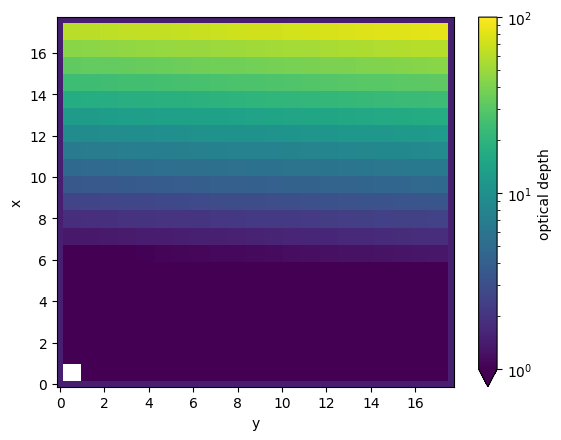

In [6]:
solvers[0.67].medium['cloud'].extinction.integrate('z').plot(vmin=1, vmax=100, cbar_kwargs={'label': 'optical depth'}, norm=colors.LogNorm())

In [7]:
forward_sensors.get_measurements(solvers)
save_sensor_dict(sd_out, forward_sensors)

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.939  0.480E+00    67600   256.00  1.000   [Radiance 0.670 micron]
     2  -1.344  0.483E+00    67600   256.00  1.000   [Radiance 0.670 micron]
     3  -1.706  0.487E+00    67600   256.00  1.000   [Radiance 0.670 micron]
     4  -1.849  0.274E+00    68059   256.00  1.000   [Radiance 0.670 micron]
     5  -2.001  0.168E+00    68482   256.00  1.000   [Radiance 0.670 micron]
     6  -2.164  0.114E+00    69364   256.00  1.000   [Radiance 0.670 micron]
     7  -2.204  0.809E-01    70066   256.00  1.000   [Radiance 0.670 micron]
     8  -2.242  0.660E-01    70462   256.00  1.000   [Radiance 0.670 micron]
     9  -2.216  0.573E-01    71596   256.00  1.000   [Radiance 0.670 micron]
    10  -2.353  0.549E-01    71893   256.00  1.000   [Radiance 0.670 micron]
    11  -2.469  0.474E-01    73261   256.00  1.000   [Radiance 0.670 micron]
    12  -2.284  0.395E-01    75709   256.00  1.000   [Radiance 0.670 micron]
  

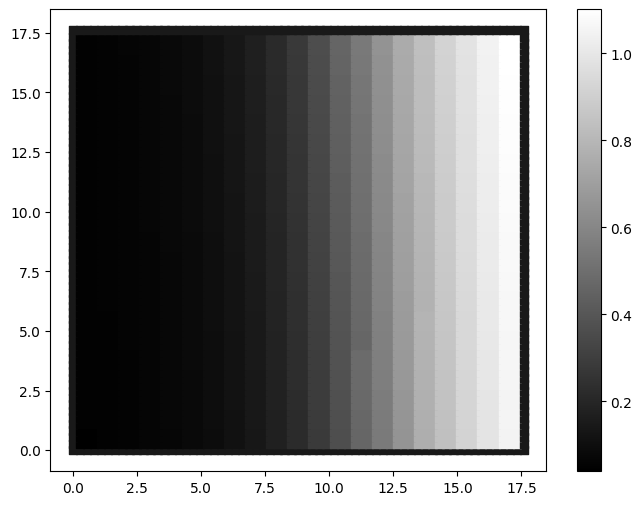

In [8]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
cam = forward_sensors['MISR']['sensor_list'][0]
c = ax.scatter(cam.ray_x.data, cam.ray_y.data, c=cam.I.data*np.pi/cam.mu0, marker='s', cmap='gray')
plt.colorbar(c, ax=ax)

In [9]:
brf = np.zeros(taus.shape)
tau_real = np.zeros(taus.shape)
cam = forward_sensors['MISR']['sensor_list'][0]
for i in range(taus.shape[0]):
    for j in range(taus.shape[1]):
        extx = 3*i + 2
        exty = 3*j + 2
        tau_real[i,j] = solvers[0.67].medium['cloud'].isel(x=extx, y=exty).extinction.integrate('z').data
        posx = extx * 0.275
        posy = exty * 0.275
        cond = (cam.ray_x.data == posx) & (cam.ray_y.data == posy)
        single_brf = cam.I.data[cond]*np.pi/cam.mu0
        assert len(single_brf) == 1
        brf[i,j] = single_brf[0]

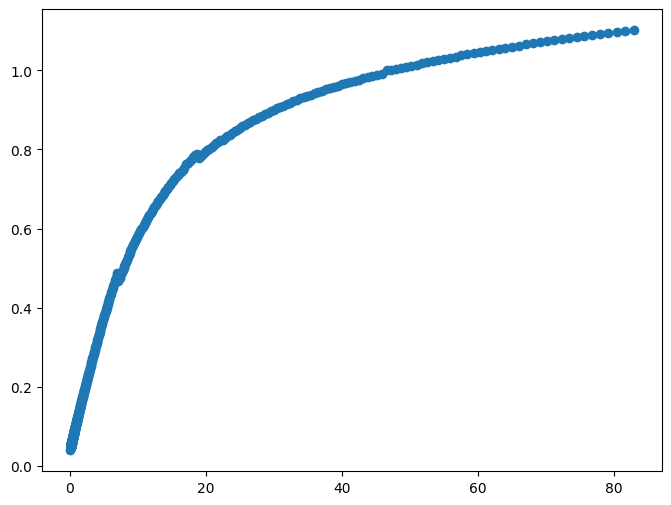

In [10]:
f, ax = plt.subplots(1, 1, figsize=(8,6))
ax.scatter(tau_real, brf)

In [11]:
LUT = xr.Dataset(
    coords=dict(
        brf=np.ravel(brf)
    ),
    data_vars=dict(
        tau=(['brf'], np.ravel(tau_real))
    )
)
LUT.to_netcdf(out_file)